# 🧩 PCA vs Kernel PCA vs Autoencoder

**Tugas 2 — Dimensionality Reduction**

Membandingkan tiga metode reduksi dimensi pada dataset **Digits** (1.797 gambar 8×8 → 64 fitur):

| Metode | Jenis |
|---|---|
| PCA | Linear |
| Kernel PCA (RBF) | Non-linear berbasis kernel |
| Autoencoder (Keras) | Non-linear berbasis neural network |

Tahapan:
1. Visualisasi *latent space* 2 dimensi
2. Akurasi **Logistic Regression** pada hasil reduksi n = 2 dan n = 10
3. *Tuning* parameter `gamma` Kernel PCA
4. Kesimpulan

TUGAS 1 & 2 — n_components / bottleneck = 2


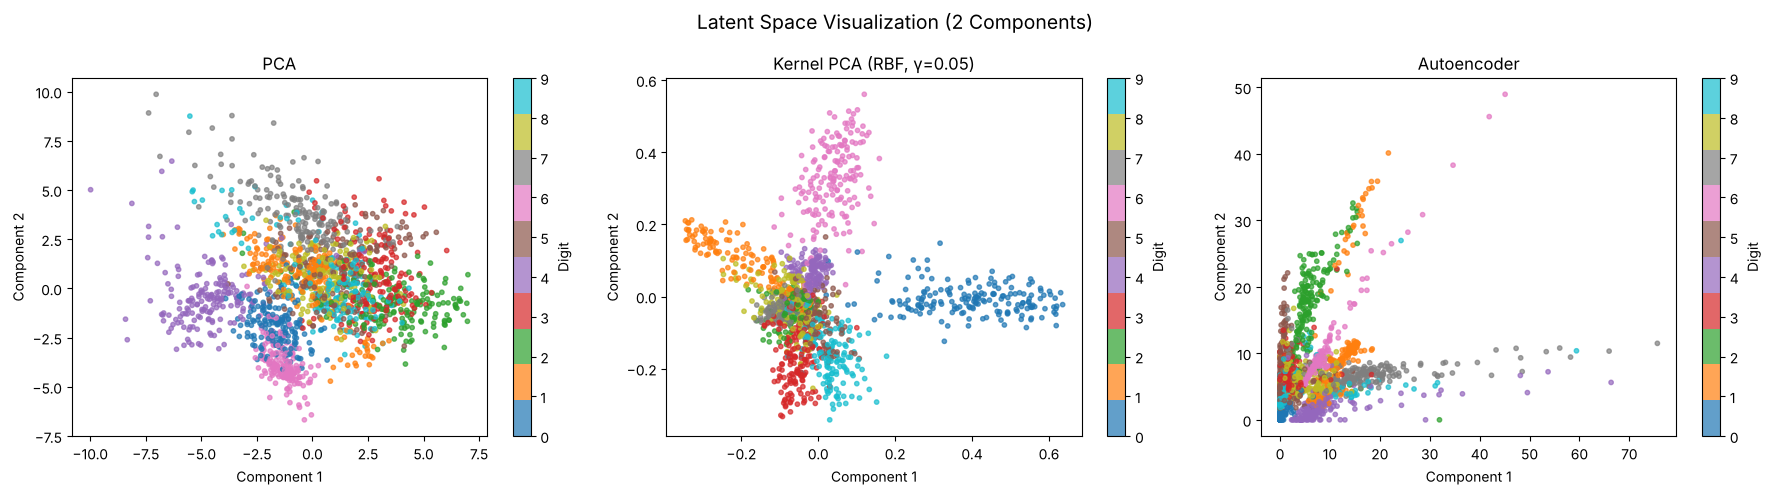


Logistic Regression Accuracy (n=2):
  [PCA] Accuracy: 0.5389 (53.89%)
  [Kernel PCA] Accuracy: 0.5361 (53.61%)
  [Autoencoder] Accuracy: 0.6139 (61.39%)

TUGAS 3 — n_components / bottleneck = 10



Logistic Regression Accuracy (n=10):
  [PCA] Accuracy: 0.8833 (88.33%)
  [Kernel PCA] Accuracy: 0.8417 (84.17%)


  [Autoencoder] Accuracy: 0.8667 (86.67%)


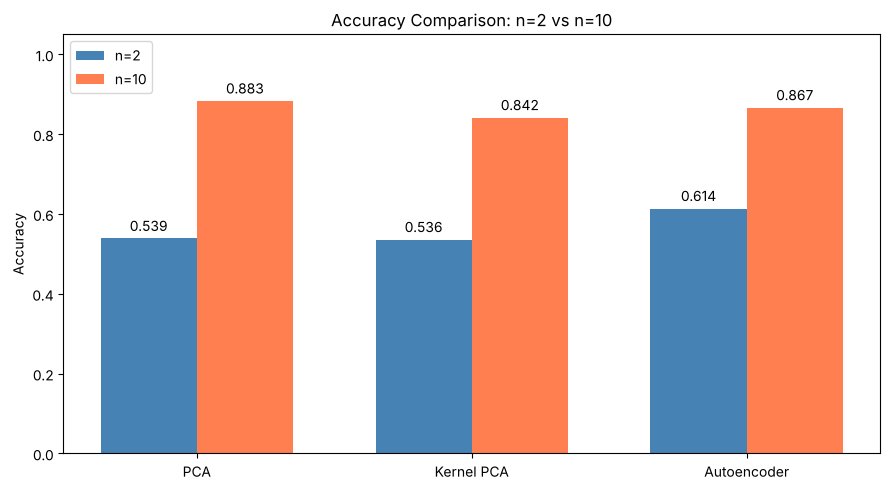


TUGAS 4 — Kernel PCA Gamma Tuning (n=10)


  [γ=0.01] Accuracy: 0.8667 (86.67%)


  [γ=0.05] Accuracy: 0.8417 (84.17%)


  [γ=0.1] Accuracy: 0.6750 (67.50%)


  [γ=0.5] Accuracy: 0.1528 (15.28%)


  [γ=1.0] Accuracy: 0.0778 (7.78%)

   Best gamma: 0.01 → Accuracy: 0.8667


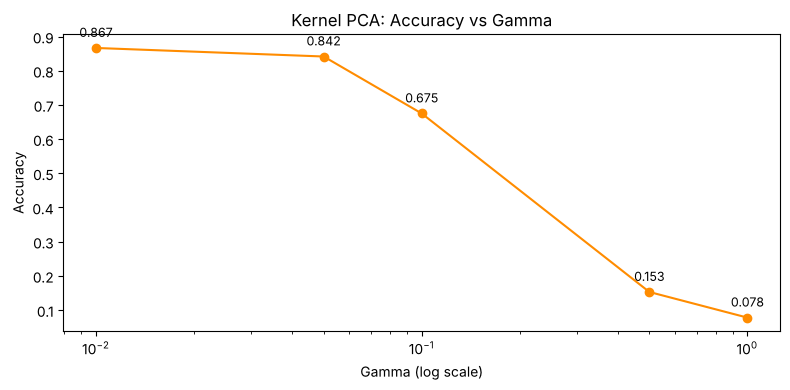


TUGAS 5 — KESIMPULAN SUMMARY

  n=2  → PCA: 0.539 | Kernel PCA: 0.536 | AE: 0.614
  n=10 → PCA: 0.883 | Kernel PCA: 0.842 | AE: 0.867
  Best Kernel PCA gamma: 0.01 → 0.867



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import os
import tensorflow as tf
from tensorflow import keras

os.makedirs("images", exist_ok=True)
tf.random.set_seed(42)
np.random.seed(42)

# ── Setup ──────────────────────────────────────────────────────────────────────
digits = load_digits()
X = digits.data        # (1797, 64)
y = digits.target      # (1797,) — label 0-9

X_scaled = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

def evaluate_lr(X_tr, X_te, y_tr, y_te, label=""):
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, clf.predict(X_te))
    print(f"  [{label}] Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    return acc

def build_autoencoder(input_dim, bottleneck):
    inp = keras.Input(shape=(input_dim,))
    encoded = keras.layers.Dense(32, activation="relu")(inp)
    encoded = keras.layers.Dense(bottleneck, activation="relu")(encoded)
    decoded = keras.layers.Dense(32, activation="relu")(encoded)
    decoded = keras.layers.Dense(input_dim, activation="linear")(decoded)

    autoencoder = keras.Model(inp, decoded)
    encoder = keras.Model(inp, encoded)
    autoencoder.compile(optimizer="adam", loss="mse")
    return autoencoder, encoder

print("=" * 60)
print("TUGAS 1 & 2 — n_components / bottleneck = 2")
print("=" * 60)

N = 2

# ── PCA ───────────────────────────────────────────────────────────────────────
pca2 = PCA(n_components=N, random_state=42)
X_pca2 = pca2.fit_transform(X_scaled)
X_train_pca2 = pca2.transform(X_train)
X_test_pca2 = pca2.transform(X_test)

# ── Kernel PCA (RBF) ──────────────────────────────────────────────────────────
kpca2 = KernelPCA(n_components=N, kernel="rbf", gamma=0.05, random_state=42)
X_kpca2 = kpca2.fit_transform(X_scaled)
X_train_kpca2 = kpca2.transform(X_train)
X_test_kpca2 = kpca2.transform(X_test)

# ── Autoencoder ───────────────────────────────────────────────────────────────
ae2, enc2 = build_autoencoder(input_dim=64, bottleneck=N)
ae2.fit(X_train, X_train, epochs=100, batch_size=32,
        validation_split=0.1, verbose=0)
X_ae2 = enc2.predict(X_scaled, verbose=0)
X_train_ae2 = enc2.predict(X_train, verbose=0)
X_test_ae2 = enc2.predict(X_test, verbose=0)

# ── Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Latent Space Visualization (2 Components)", fontsize=14)

for ax, Z, title in zip(
    axes,
    [X_pca2, X_kpca2, X_ae2],
    ["PCA", "Kernel PCA (RBF, γ=0.05)", "Autoencoder"]
):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=10, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    plt.colorbar(sc, ax=ax, label="Digit")

plt.tight_layout()
plt.savefig("images/latent_space_2.png", dpi=150)
plt.show()

# ── Logistic Regression (n=2) ─────────────────────────────────────────────────
print("\nLogistic Regression Accuracy (n=2):")
acc_pca2 = evaluate_lr(X_train_pca2, X_test_pca2, y_train, y_test, "PCA")
acc_kpca2 = evaluate_lr(X_train_kpca2, X_test_kpca2, y_train, y_test, "Kernel PCA")
acc_ae2 = evaluate_lr(X_train_ae2, X_test_ae2, y_train, y_test, "Autoencoder")


print("\n" + "=" * 60)
print("TUGAS 3 — n_components / bottleneck = 10")
print("=" * 60)

N = 10

pca10 = PCA(n_components=N, random_state=42)
X_train_pca10 = pca10.fit_transform(X_train)
X_test_pca10 = pca10.transform(X_test)

kpca10 = KernelPCA(n_components=N, kernel="rbf", gamma=0.05, random_state=42)
X_train_kpca10 = kpca10.fit_transform(X_train)
X_test_kpca10 = kpca10.transform(X_test)

ae10, enc10 = build_autoencoder(input_dim=64, bottleneck=N)
ae10.fit(X_train, X_train, epochs=100, batch_size=32,
         validation_split=0.1, verbose=0)
X_train_ae10 = enc10.predict(X_train, verbose=0)
X_test_ae10 = enc10.predict(X_test, verbose=0)

print("\nLogistic Regression Accuracy (n=10):")
acc_pca10 = evaluate_lr(X_train_pca10, X_test_pca10, y_train, y_test, "PCA")
acc_kpca10 = evaluate_lr(X_train_kpca10, X_test_kpca10, y_train, y_test, "Kernel PCA")
acc_ae10 = evaluate_lr(X_train_ae10, X_test_ae10, y_train, y_test, "Autoencoder")

# ── Bar chart comparison ──────────────────────────────────────────────────────
methods = ["PCA", "Kernel PCA", "Autoencoder"]
accs_2 = [acc_pca2, acc_kpca2, acc_ae2]
accs_10 = [acc_pca10, acc_kpca10, acc_ae10]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(x - width / 2, accs_2, width, label="n=2", color="steelblue")
bars2 = ax.bar(x + width / 2, accs_10, width, label="n=10", color="coral")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy Comparison: n=2 vs n=10")
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 1.05)
ax.legend()
ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)
plt.tight_layout()
plt.savefig("images/accuracy_comparison.png", dpi=150)
plt.show()

print("\n" + "=" * 60)
print("TUGAS 4 — Kernel PCA Gamma Tuning (n=10)")
print("=" * 60)

gammas = [0.01, 0.05, 0.1, 0.5, 1.0]
gamma_accs = []

for g in gammas:
    kpca_g = KernelPCA(n_components=10, kernel="rbf", gamma=g, random_state=42)
    Xtr_g = kpca_g.fit_transform(X_train)
    Xte_g = kpca_g.transform(X_test)
    acc_g = evaluate_lr(Xtr_g, Xte_g, y_train, y_test, f"γ={g}")
    gamma_accs.append(acc_g)

best_gamma = gammas[np.argmax(gamma_accs)]
print(f"\n   Best gamma: {best_gamma} → Accuracy: {max(gamma_accs):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(gammas, gamma_accs, marker="o", color="darkorange")
plt.xscale("log")
plt.xlabel("Gamma (log scale)")
plt.ylabel("Accuracy")
plt.title("Kernel PCA: Accuracy vs Gamma")
for g, a in zip(gammas, gamma_accs):
    plt.annotate(f"{a:.3f}", (g, a), textcoords="offset points",
                 xytext=(0, 8), ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("images/kpca_gamma.png", dpi=150)
plt.show()

print("\n" + "=" * 60)
print("TUGAS 5 — KESIMPULAN SUMMARY")
print("=" * 60)
print(f"""
  n=2  → PCA: {acc_pca2:.3f} | Kernel PCA: {acc_kpca2:.3f} | AE: {acc_ae2:.3f}
  n=10 → PCA: {acc_pca10:.3f} | Kernel PCA: {acc_kpca10:.3f} | AE: {acc_ae10:.3f}
  Best Kernel PCA gamma: {best_gamma} → {max(gamma_accs):.3f}
""")